# Twitter Sentiment Analysis Using Machine Learning

**Goal:** classify tweets as *positive* or *negative* using classic machine learning (TF-IDF + Logistic Regression / Linear SVM / Naive Bayes), then save the best model for the Streamlit demo (`app.py`).

**Dataset:** [Sentiment140](https://www.kaggle.com/datasets/kazanova/sentiment140) (1.6 million tweets, labelled `0` = negative and `4` = positive).

**Pipeline:** load data → explore → balanced sample → clean text → visualise → split → TF-IDF → train 3 models → evaluate → save → try your own text.

### How to run
1. Download `training.1600000.processed.noemoticon.csv` from Kaggle and put it in the `data/` folder.
2. Run all cells (*Kernel → Restart & Run All*).

If the full file is not found, the notebook falls back to `data/sample.csv`, a small **synthetic mock** file that is only good for checking that the code runs. Never report results from the mock file.

## 1. Imports and settings

In [1]:
import json
import sys
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

# the notebook lives in notebooks/, the project root is one level up
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from sentiment_utils import clean_text, positive_scores, predict_sentiment

FULL_PATH = ROOT / "data" / "training.1600000.processed.noemoticon.csv"
SAMPLE_PATH = ROOT / "data" / "sample.csv"
MODELS_DIR = ROOT / "models"

SAMPLES_PER_CLASS = 50_000   # 50k negative + 50k positive; lower it if your laptop is slow
TEST_SIZE = 0.20
SEED = 42

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

USING_SAMPLE = not FULL_PATH.exists()
DATA_PATH = SAMPLE_PATH if USING_SAMPLE else FULL_PATH
print("Data file:", DATA_PATH)
if USING_SAMPLE:
    print("\n*** WARNING: using the synthetic MOCK sample. Results are meaningless. ***")

Data file: D:\sentiment-analysis\sentiment-analysis\data\training.1600000.processed.noemoticon.csv


## 2. Load the data

The Kaggle file has **no header row** and uses `latin-1` encoding. Its six columns are: `target, id, date, flag, user, text`. We only need the label (column 0) and the text (column 5), so we load just those two to save memory.

In [2]:
df = pd.read_csv(DATA_PATH, encoding="latin-1", header=None,
                 usecols=[0, 5], names=["target", "text"])
df.head()

,target,text
0,0,"@switchfoot http://twitpic.com/2y1zl - Awww, t..."
1,0,is upset that he can't update his Facebook by ...
2,0,@Kenichan I dived many times for the ball. Man...
3,0,my whole body feels itchy and like its on fire
4,0,"@nationwideclass no, it's not behaving at all...."


## 3. Exploratory data analysis

In [3]:
print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())
print("\nRaw label counts (0 = negative, 4 = positive):\n", df["target"].value_counts())
print("\nExact duplicate tweets:", df["text"].duplicated().sum())
assert set(df["target"].unique()) <= {0, 4}, "Unexpected label values"
df.info()

Shape: (1600000, 2)

Missing values:
 target    0
text      0
dtype: int64

Raw label counts (0 = negative, 4 = positive):
 target
0    800000
4    800000
Name: count, dtype: int64

Exact duplicate tweets: 18534
<class 'pandas.DataFrame'>
RangeIndex: 1600000 entries, 0 to 1599999
Data columns (total 2 columns):
 #   Column  Non-Null Count    Dtype
---  ------  --------------    -----
 0   target  1600000 non-null  int64
 1   text    1600000 non-null  str  
dtypes: int64(1), str(1)
memory usage: 137.6 MB


### Prepare the labels and build a balanced sample

* map `4 → 1` so labels are `0` / `1`
* drop missing tweets and **exact duplicates** (duplicates can land in both train and test and inflate accuracy)
* take the same number of tweets from each class

In [4]:
df = df.dropna(subset=["text"]).drop_duplicates(subset="text").copy()
df["label"] = (df["target"] == 4).astype(int)

n_per_class = int(min(SAMPLES_PER_CLASS, df["label"].value_counts().min()))
df = (df.groupby("label").sample(n=n_per_class, random_state=SEED)
        .sample(frac=1, random_state=SEED)          # shuffle
        .reset_index(drop=True))
df["label_name"] = df["label"].map({0: "Negative", 1: "Positive"})

print(f"Using {len(df):,} tweets ({n_per_class:,} per class)")
df[["label_name", "text"]].head(8)

Using 10,000 tweets (5,000 per class)


,label_name,text
0,Positive,just saw the New Moon preview on the MTV Movie...
1,Negative,"&quot;I want action tonight, satisfation all n..."
2,Negative,ugh. i have to eat lunch now. please be here w...
3,Negative,@Pippi43 well i'll try to work around whenever...
4,Negative,@i102104 some other station is broadcasting in...
5,Positive,@bep mad song guys
6,Negative,watched official video of white horse by tswif...
7,Positive,Blindy it's hot today! Nice milkshake to offse...


### Visualise the class balance and tweet length

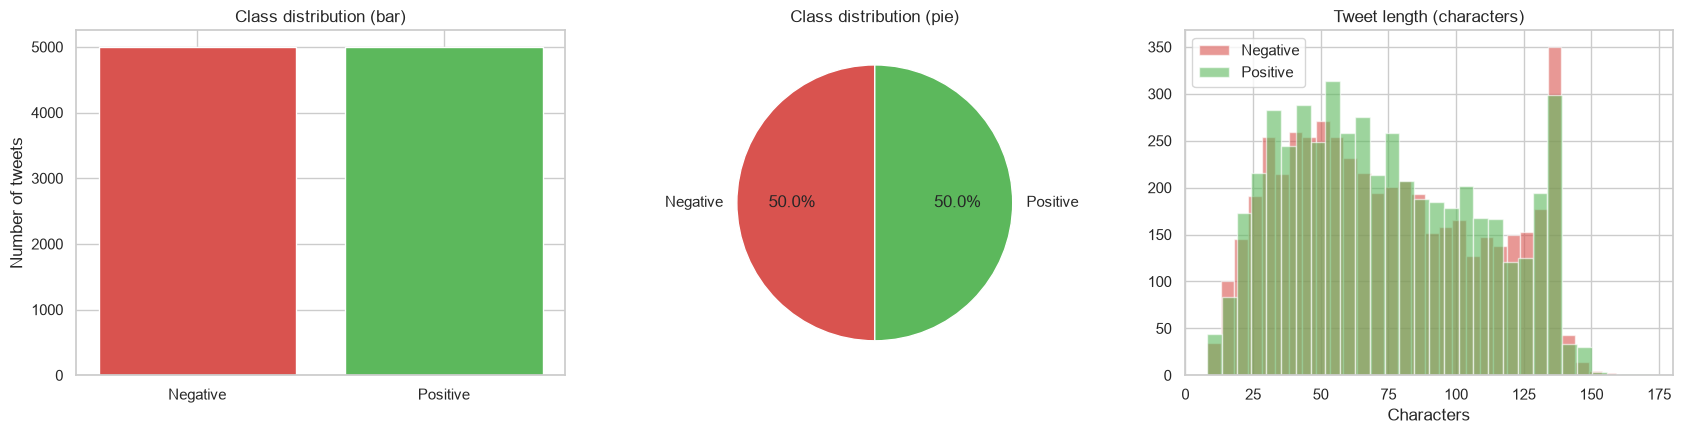

,count,mean,std,min,25%,50%,75%,max
label_name,,,,,,,,
Negative,5000.0,75.1,36.6,8.0,45.0,71.0,106.0,159.0
Positive,5000.0,74.5,35.9,8.0,45.0,70.0,103.0,172.0


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

counts = df["label_name"].value_counts().reindex(["Negative", "Positive"])
axes[0].bar(counts.index, counts.values, color=["#d9534f", "#5cb85c"])
axes[0].set_title("Class distribution (bar)")
axes[0].set_ylabel("Number of tweets")

axes[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%",
            colors=["#d9534f", "#5cb85c"], startangle=90)
axes[1].set_title("Class distribution (pie)")

df["char_length"] = df["text"].str.len()
for name, colour in [("Negative", "#d9534f"), ("Positive", "#5cb85c")]:
    axes[2].hist(df.loc[df["label_name"] == name, "char_length"], bins=30,
                 alpha=0.6, label=name, color=colour)
axes[2].set_title("Tweet length (characters)")
axes[2].set_xlabel("Characters")
axes[2].legend()

plt.tight_layout()
plt.show()
df.groupby("label_name")["char_length"].describe().round(1)

## 4. Text preprocessing

The cleaning function lives in `sentiment_utils.py` so the Streamlit app uses *exactly* the same steps:

1. decode HTML entities (`&amp;` → `&`) and lowercase
2. remove URLs and `@mentions`, keep hashtag words
3. expand `n't` → `not` (and fix `dont`, `cant`, `didnt` → `not`)
4. keep letters only (removes numbers, punctuation, emojis)
5. shorten stretched letters (`sooooo` → `soo`)
6. remove stop words, but **keep negations and intensifiers** such as *not, no, never, very, too*
7. drop one-letter tokens

**Design choice:** there is no stemming or lemmatization. Bigram TF-IDF already captures most word-form variation in short tweets, and keeping the cleaner free of extra downloads guarantees identical behaviour in the app. Adding it is a good experiment (see the README ideas).

**Important:** the cleaned text goes into a *new column* and **that column is what the model trains on**.

In [6]:
df["clean_text"] = df["text"].apply(clean_text)

# some tweets become empty after cleaning (e.g. only a URL); remove them and any new duplicates
df = df[df["clean_text"].str.len() > 0].drop_duplicates(subset="clean_text").reset_index(drop=True)
print(f"{len(df):,} tweets after cleaning")
print(df["label_name"].value_counts().to_string())

df[["text", "clean_text"]].sample(8, random_state=SEED)

9,811 tweets after cleaning
label_name
Negative    4927
Positive    4884


,text,clean_text
3114,@ddlovato hey demi how you goin?,hey demi goin
4978,"free to download smileys and avatars, free to ...",free download smileys avatars free read view c...
1569,I still miss Kisay.,miss kisay
764,Any advice for a dead flip video? Still not wo...,advice dead flip video not working does not re...
7296,"@YoungQ Ohh, well I hope it all goes well and ...",ohh well hope goes well fun chat later
8973,"@BroccoliTofu actually thats a long story, whi...",actually thats long story moral never too invo...
1791,Feels ill since she been Kelvins,feels ill kelvins
9038,"@RealShamu Wow, that is great!! I'll do that! ...",wow great ll sorry misunderstanding soon going...


### Most frequent words per class

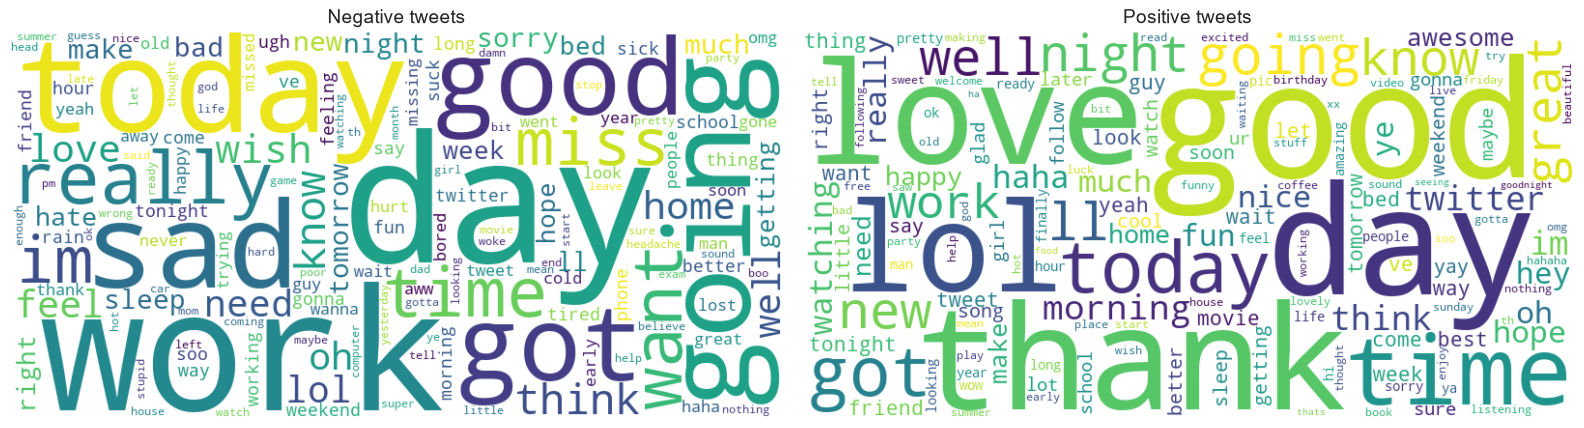

In [7]:
try:
    from wordcloud import WordCloud
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    for ax, (name, label) in zip(axes, [("Negative", 0), ("Positive", 1)]):
        words = " ".join(df.loc[df["label"] == label, "clean_text"])
        cloud = WordCloud(width=800, height=400, background_color="white",
                          max_words=150, collocations=False).generate(words)
        ax.imshow(cloud, interpolation="bilinear")
        ax.set_title(f"{name} tweets", fontsize=14)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("wordcloud is not installed (pip install wordcloud). Skipping word clouds.")

## 5. Train / test split and TF-IDF features

* **80 / 20 split, stratified** so both sets keep the same class balance (the old notebook used only 5% for testing).
* The vectorizer is **fitted on the training set only**, then applied to the test set.
* Unigrams + bigrams (`not good` becomes a feature of its own).

In [8]:
train_df, test_df = train_test_split(df, test_size=TEST_SIZE, stratify=df["label"], random_state=SEED)

vectorizer = TfidfVectorizer(ngram_range=(1, 2), max_features=50_000, min_df=2, sublinear_tf=True)
X_train = vectorizer.fit_transform(train_df["clean_text"])   # fit on TRAIN only
X_test = vectorizer.transform(test_df["clean_text"])
y_train = train_df["label"].values
y_test = test_df["label"].values

print(f"Train: {X_train.shape[0]:,} tweets | Test: {X_test.shape[0]:,} tweets | Features: {X_train.shape[1]:,}")

Train: 7,848 tweets | Test: 1,963 tweets | Features: 6,865


## 6. Train and evaluate the models

Three classic text classifiers, from simple to stronger:

* **Multinomial Naive Bayes**: fast probabilistic baseline
* **Logistic Regression**: strong, interpretable linear model
* **Linear SVM**: often the best linear model for sparse text

Metrics: accuracy, precision, recall, F1 (positive class), confusion matrix and ROC-AUC. The ROC curve uses the model's **scores**, not hard 0/1 predictions.

In [9]:
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(C=2, max_iter=1000),
    "Linear SVM": LinearSVC(),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    scores = positive_scores(model, X_test)
    results[name] = {
        "y_pred": y_pred,
        "scores": scores,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, scores),
    }
    print(f"\n===== {name} =====")
    print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=3))


===== Naive Bayes =====
              precision    recall  f1-score   support

    Negative      0.699     0.772     0.733       986
    Positive      0.743     0.664     0.701       977

    accuracy                          0.718      1963
   macro avg      0.721     0.718     0.717      1963
weighted avg      0.721     0.718     0.717      1963


===== Logistic Regression =====
              precision    recall  f1-score   support

    Negative      0.745     0.757     0.751       986
    Positive      0.750     0.738     0.744       977

    accuracy                          0.747      1963
   macro avg      0.747     0.747     0.747      1963
weighted avg      0.747     0.747     0.747      1963


===== Linear SVM =====
              precision    recall  f1-score   support

    Negative      0.720     0.735     0.728       986
    Positive      0.727     0.711     0.719       977

    accuracy                          0.723      1963
   macro avg      0.723     0.723     0.723   

### Confusion matrices

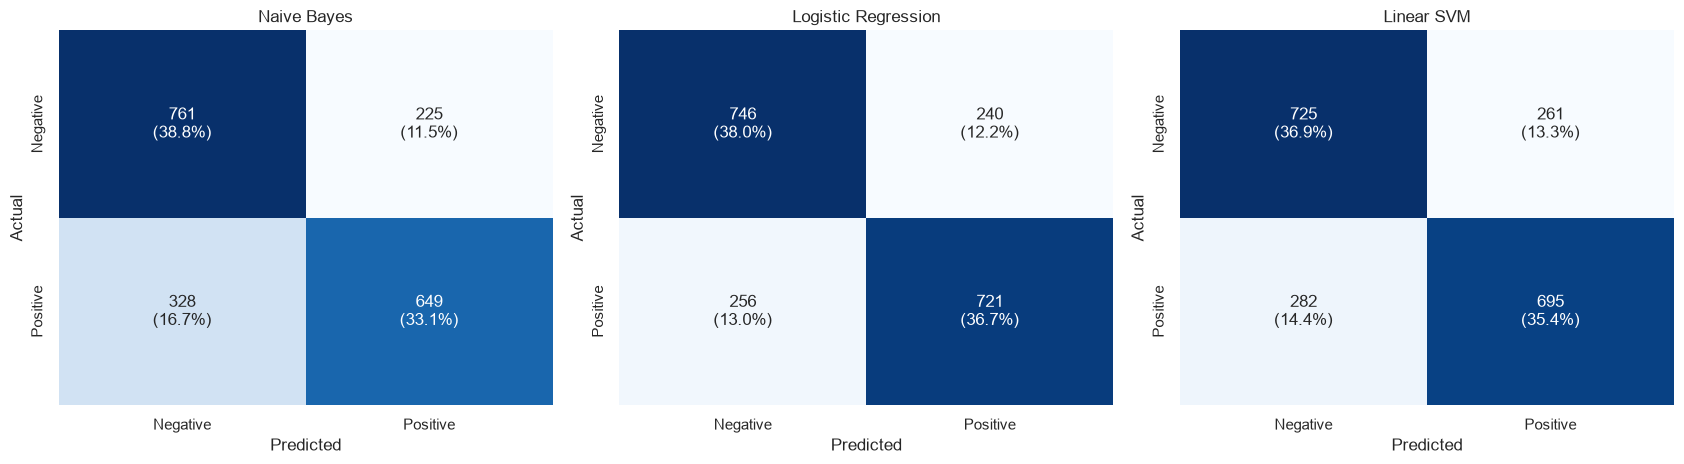

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
class_names = ["Negative", "Positive"]
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, r["y_pred"])
    pct = cm / cm.sum()
    annot = np.array([[f"{cm[i, j]}\n({pct[i, j]:.1%})" for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

### ROC curves (from scores) and model comparison

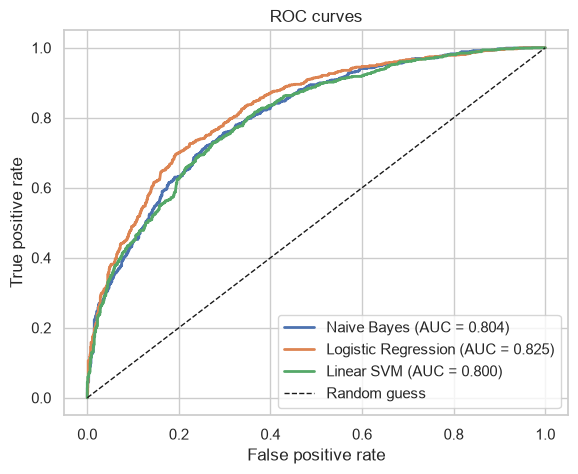

,Accuracy,Precision,Recall,F1,ROC-AUC
Naive Bayes,0.7183,0.7426,0.6643,0.7012,0.8037
Logistic Regression,0.7473,0.7503,0.7380,0.7441,0.8252
Linear SVM,0.7234,0.7270,0.7114,0.7191,0.8000


In [11]:
plt.figure(figsize=(6.5, 5))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["scores"])
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {r['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curves")
plt.legend(loc="lower right")
plt.show()

metric_cols = ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]
summary = pd.DataFrame({name: {m: r[m] for m in metric_cols} for name, r in results.items()}).T
summary.round(4)

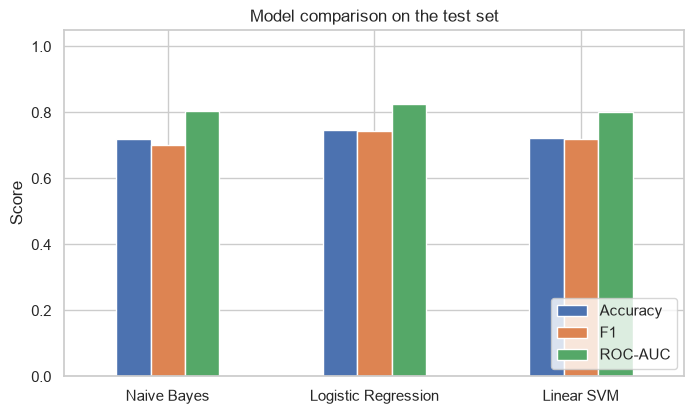

In [12]:
summary[["Accuracy", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(8, 4.5), rot=0)
plt.title("Model comparison on the test set")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend(loc="lower right")
plt.show()

### Cross-validation (is the result stable?)

A single split can be lucky. Here each model is scored on 3 different training folds (F1, positive class). A small standard deviation means the ranking is reliable. If two models are within about one standard deviation of each other, treat them as tied.

In [13]:
cv_rows = {}
for name, model in models.items():
    cv_scores = cross_val_score(clone(model), X_train, y_train, cv=3, scoring="f1")
    cv_rows[name] = {"CV F1 mean": cv_scores.mean(), "CV F1 std": cv_scores.std()}
pd.DataFrame(cv_rows).T.round(4)

,CV F1 mean,CV F1 std
Naive Bayes,0.7129,0.0093
Logistic Regression,0.7331,0.0106
Linear SVM,0.7158,0.0061


## 7. What did the model learn?

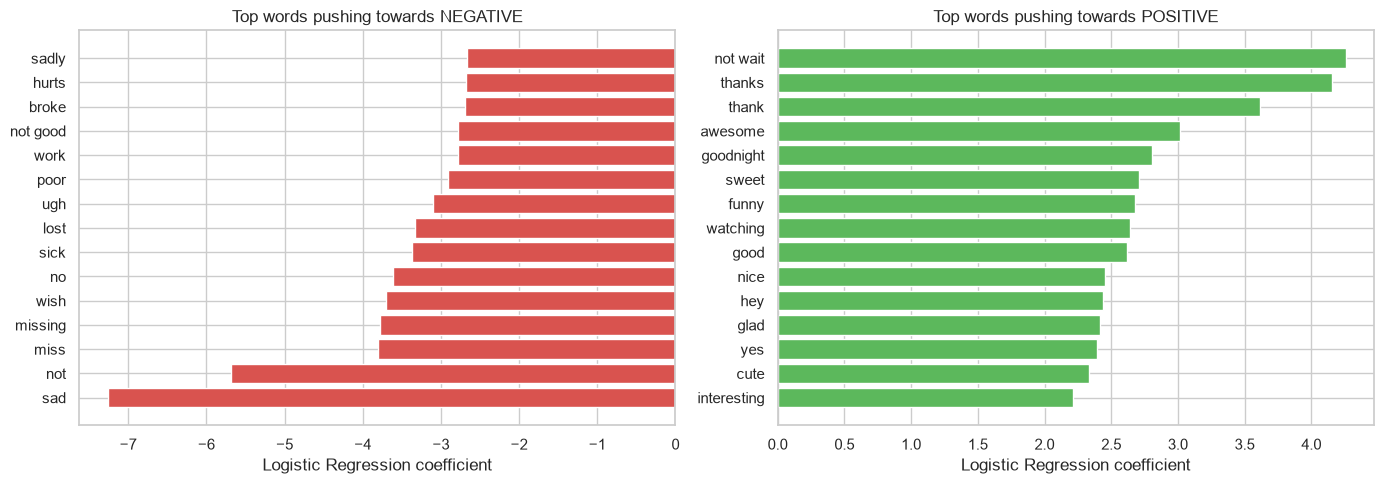

In [14]:
lr = models["Logistic Regression"]
feature_names = np.array(vectorizer.get_feature_names_out())
order = np.argsort(lr.coef_[0])
top_neg, top_pos = order[:15], order[-15:]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(feature_names[top_neg], lr.coef_[0][top_neg], color="#d9534f")
axes[0].set_title("Top words pushing towards NEGATIVE")
axes[1].barh(feature_names[top_pos], lr.coef_[0][top_pos], color="#5cb85c")
axes[1].set_title("Top words pushing towards POSITIVE")
for ax in axes:
    ax.set_xlabel("Logistic Regression coefficient")
plt.tight_layout()
plt.show()

### Error analysis

Looking at mistakes teaches you more than the accuracy number. Typical causes on Sentiment140: sarcasm, very short tweets, negation, and noisy labels (the labels come from emoticons, not human judgement).

In [15]:
best_name = summary["F1"].idxmax()
print("Best model by F1:", best_name)

errors = test_df.assign(predicted=results[best_name]["y_pred"])
errors = errors[errors["label"] != errors["predicted"]].copy()
errors["actual_name"] = errors["label"].map({0: "Negative", 1: "Positive"})
errors["predicted_name"] = errors["predicted"].map({0: "Negative", 1: "Positive"})
print(f"{len(errors):,} of {len(test_df):,} test tweets misclassified")
errors[["text", "actual_name", "predicted_name"]].head(8)

Best model by F1: Logistic Regression
496 of 1,963 test tweets misclassified


,text,actual_name,predicted_name
1973,@zelciia weird. I tot it will usually rain eas...,Positive,Negative
8716,Okay I graduated,Positive,Negative
6523,Walking to church with tummy full of warm star...,Positive,Negative
7353,"@adecembertruth hey adt, guess what. my prince...",Positive,Negative
7234,doing artwork in my garage! havent felt art in...,Positive,Negative
5641,On my way home from london,Negative,Positive
4401,whatttttttttttt... a weekend,Positive,Negative
5458,"phwoarrr, havent been on here in a while im t...",Positive,Negative


## 8. Save the best model for the Streamlit app

The vectorizer and model are saved separately with `joblib`, plus a small `metadata.json` that the app shows in its sidebar. The best model is picked by F1 on the test set; for a stricter protocol you would pick it on a separate validation set.

In [16]:
MODELS_DIR.mkdir(exist_ok=True)
joblib.dump(vectorizer, MODELS_DIR / "vectorizer.joblib")
joblib.dump(models[best_name], MODELS_DIR / "model.joblib")

metadata = {
    "model_name": best_name,
    "metrics": {m: round(float(summary.loc[best_name, m]), 4) for m in metric_cols},
    "n_train": int(X_train.shape[0]),
    "n_test": int(X_test.shape[0]),
    "data_source": "MOCK sample (synthetic)" if USING_SAMPLE else "Sentiment140",
    "sklearn_version": sklearn.__version__,
    "trained_at": datetime.now().strftime("%Y-%m-%d %H:%M"),
}
(MODELS_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
print(json.dumps(metadata, indent=2))

{
  "model_name": "Logistic Regression",
  "metrics": {
    "Accuracy": 0.7473,
    "Precision": 0.7503,
    "Recall": 0.738,
    "F1": 0.7441,
    "ROC-AUC": 0.8252
  },
  "n_train": 7848,
  "n_test": 1963,
  "data_source": "Sentiment140",
  "sklearn_version": "1.9.1",
  "trained_at": "2026-11-01 15:10"
}


## 9. Try your own text

The model learned from **tweets**, so other writing styles (like product reviews) may be predicted less reliably. Texts whose score falls near the middle are labelled *Uncertain* instead of being forced into a class.

In [17]:
examples = [
    "I love this phone, the battery lasts forever!",
    "This is not good at all, total waste of money",
    "The delivery was late and the box was damaged",
    "Not bad, actually quite happy with it",
    "It arrived on Tuesday.",
]
pd.DataFrame(predict_sentiment(examples, vectorizer, models[best_name]))[["text", "label", "positive_score"]].round(3)

,text,label,positive_score
0,"I love this phone, the battery lasts forever!",Positive,0.713
1,"This is not good at all, total waste of money",Negative,0.394
2,The delivery was late and the box was damaged,Positive,0.771
3,"Not bad, actually quite happy with it",Uncertain,0.502
4,It arrived on Tuesday.,Uncertain,0.482


## 10. Conclusions (write these yourself)

Fill this in using **your own results** from the tables and plots above:

1. Which model performed best, and by how much? Are the top models really different once you look at the cross-validation standard deviation?
2. Which class is harder to predict, and what do the confusion matrices show?
3. What did the top words and the error analysis reveal?
4. **Limitations:** labels come from emoticons (noisy); only two classes (no neutral); sarcasm and slang; the model learned from 2009 tweets; a small sample was used (`SAMPLES_PER_CLASS`).
5. What would you try next? (stemming or lemmatization, more data, a neutral class, a transformer model such as DistilBERT)